# Assess total ICESat-2 candidate training obs for 2020 in boreal and >51.6

In [1]:
library(aws.s3)
library(tidyverse)
library(sf)
library(viridis)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.1     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.4     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Linking to GEOS 3.12.1, GDAL 3.8.5, PROJ 9.4.0; sf_use_s2() is TRUE

Loading required package: viridisLite



In [2]:
#library(aws.s3)
#library(rgdal)
library(raster)
library(tidyverse)
library(dplyr)
library(grid)
library(gridExtra)
library(RColorBrewer)
library(data.table)

library(fs)
library(sf)
#library(rgdal)


#library(rgeos)
library(mapproj)
#library(rgee)
#library(viridis)
#library(wesanderson)
library(scales)
library(tools)
#library(patchwork)

library(rnaturalearth)
library(rnaturalearthdata)
#library(feather)

#conda install -c conda-forge r-rnaturalearth r-rnaturalearthdata r-mapproj r-rgeos r-viridis r-wesanderson r-patchwork r-aws.s3 r-feather r-rockchalk

Loading required package: sp


Attaching package: ‘raster’


The following object is masked from ‘package:dplyr’:

    select



Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine



Attaching package: ‘data.table’


The following object is masked from ‘package:raster’:

    shift


The following objects are masked from ‘package:lubridate’:

    hour, isoweek, mday, minute, month, quarter, second, wday, week,
    yday, year


The following objects are masked from ‘package:dplyr’:

    between, first, last


The following object is masked from ‘package:purrr’:

    transpose


Loading required package: maps


Attaching package: ‘maps’


The following object is masked from ‘package:viridis’:

    unemp


The following object is masked from ‘package:purrr’:

    map



Attaching package: ‘scales’


The following object is masked from ‘package:viridis’:

    viridis_pal


The following object is masked from ‘package:purrr’:

    discard


The

## Set output figure dir.

In [3]:
OUT_FIGURE_DIR = '/projects/my-public-bucket/boreal_AGB/paper_figs'
DATA_DIR_ATL08_SMRY = paste0('/projects/my-public-bucket/boreal_HLS_ATL08_metadata', '/data')
dir.create(OUT_FIGURE_DIR)

Warning message in dir.create(OUT_FIGURE_DIR):
“'/projects/my-public-bucket/boreal_AGB/paper_figs' already exists”


### Mapping functions and vars

In [4]:
source('/projects/code/3dsi/boreal_map_functions.R') 

[1] "MAAP"
[1] "MAAP"


In [8]:
crs_canalb = "+proj=aea +lat_0=40 +lon_0=180 +lat_1=50 +lat_2=70 +x_0=0 +y_0=0 +datum=NAD83 +units=m +no_defs"
crs_albers = "+proj=aea +lat_1=50 +lat_2=70 +lat_0=40 +lon_0=180 +x_0=0 +y_0=0 +ellps=GRS80 +datum=NAD83 +units=m +no_defs"
crs_gcs = "+proj=longlat +ellps=WGS84 +datum=WGS84 +no_defs"

### This file has the tiles used for the 2020 map (boreal and >51.6) (DAAC)

In [9]:
boreal_tile_index_path = '/projects/my-public-bucket/databank/daac/boreal_tiles_v004_ORNLDAAC.gpkg'

In [10]:
boreal_tindex = st_read(boreal_tile_index_path) %>% sf::st_transform(4326)

Reading layer `boreal_tiles_v004_ORNLDAAC' from data source 
  `/projects/my-public-bucket/databank/daac/boreal_tiles_v004_ORNLDAAC.gpkg' 
  using driver `GPKG'
Simple feature collection with 3902 features and 1 field
Geometry type: POLYGON
Dimension:     XY
Bounding box:  xmin: -180 ymin: 43.75195 xmax: 180 ymax: 78.53133
Geodetic CRS:  WGS 84


### This tindex has n_obs (candidate training) per tile

In [2]:
ATL08_filt_tindex_fn = '/projects/my-public-bucket/DPS_tile_lists/ATL08/extract_atl08_covars/2020/ATL08_filt_extract_tindex_master.csv'

In [5]:
tindex_atl08 = read.csv(ATL08_filt_tindex_fn)

In [4]:
dim(tindex_atl08)

[1] 4956    7

### This file holds the 2020 boreal-wide sample of candidate training 

In [14]:
boreal_training_atl08_csv_fn = '/projects/my-public-bucket/DPS_tile_lists/BOREAL_ATL08_TRAIN/boreal_train_data_2020_n10_diffday0.csv'

In [62]:
boreal_training_atl08_sub = boreal_training_atl08 %>% 
    #st_transform(crs=crs_albers) %>%
    dplyr::mutate(
                    lon = st_coordinates(.)[,1],  
                    lat = st_coordinates(.)[,2],
                    date = as.Date(paste(y, doy), format = "%Y %j"), # .x b/c they come from mergeneighbors
                    month = lubridate::month(date, label = TRUE)
            ) %>%
    dplyr::select(h_canopy,lon,lat,month,date,geometry) %>%
    st_intersection(boreal_tindex)

although coordinates are longitude/latitude, st_intersection assumes that they
are planar



In [63]:
head(boreal_training_atl08_sub)

,h_canopy,lon,lat,month,date,tile_num,geometry
,<dbl>,<dbl>,<dbl>,<ord>,<date>,<dbl>,<POINT [°]>
12837,7.781738,12.73449,65.43740,Aug,2020-08-18,133,POINT (12.73449 65.4374)
12838,17.105026,12.66218,65.42911,Aug,2020-08-18,133,POINT (12.66218 65.42911)
12839,6.388397,12.67356,65.20793,Aug,2020-08-18,133,POINT (12.67356 65.20793)
12840,16.935920,12.68531,65.25222,Aug,2020-08-18,133,POINT (12.68531 65.25222)
12841,8.334290,12.64626,65.62851,Aug,2020-08-18,133,POINT (12.64626 65.62851)
12842,2.405701,12.60102,65.19633,Aug,2020-08-18,133,POINT (12.60102 65.19633)


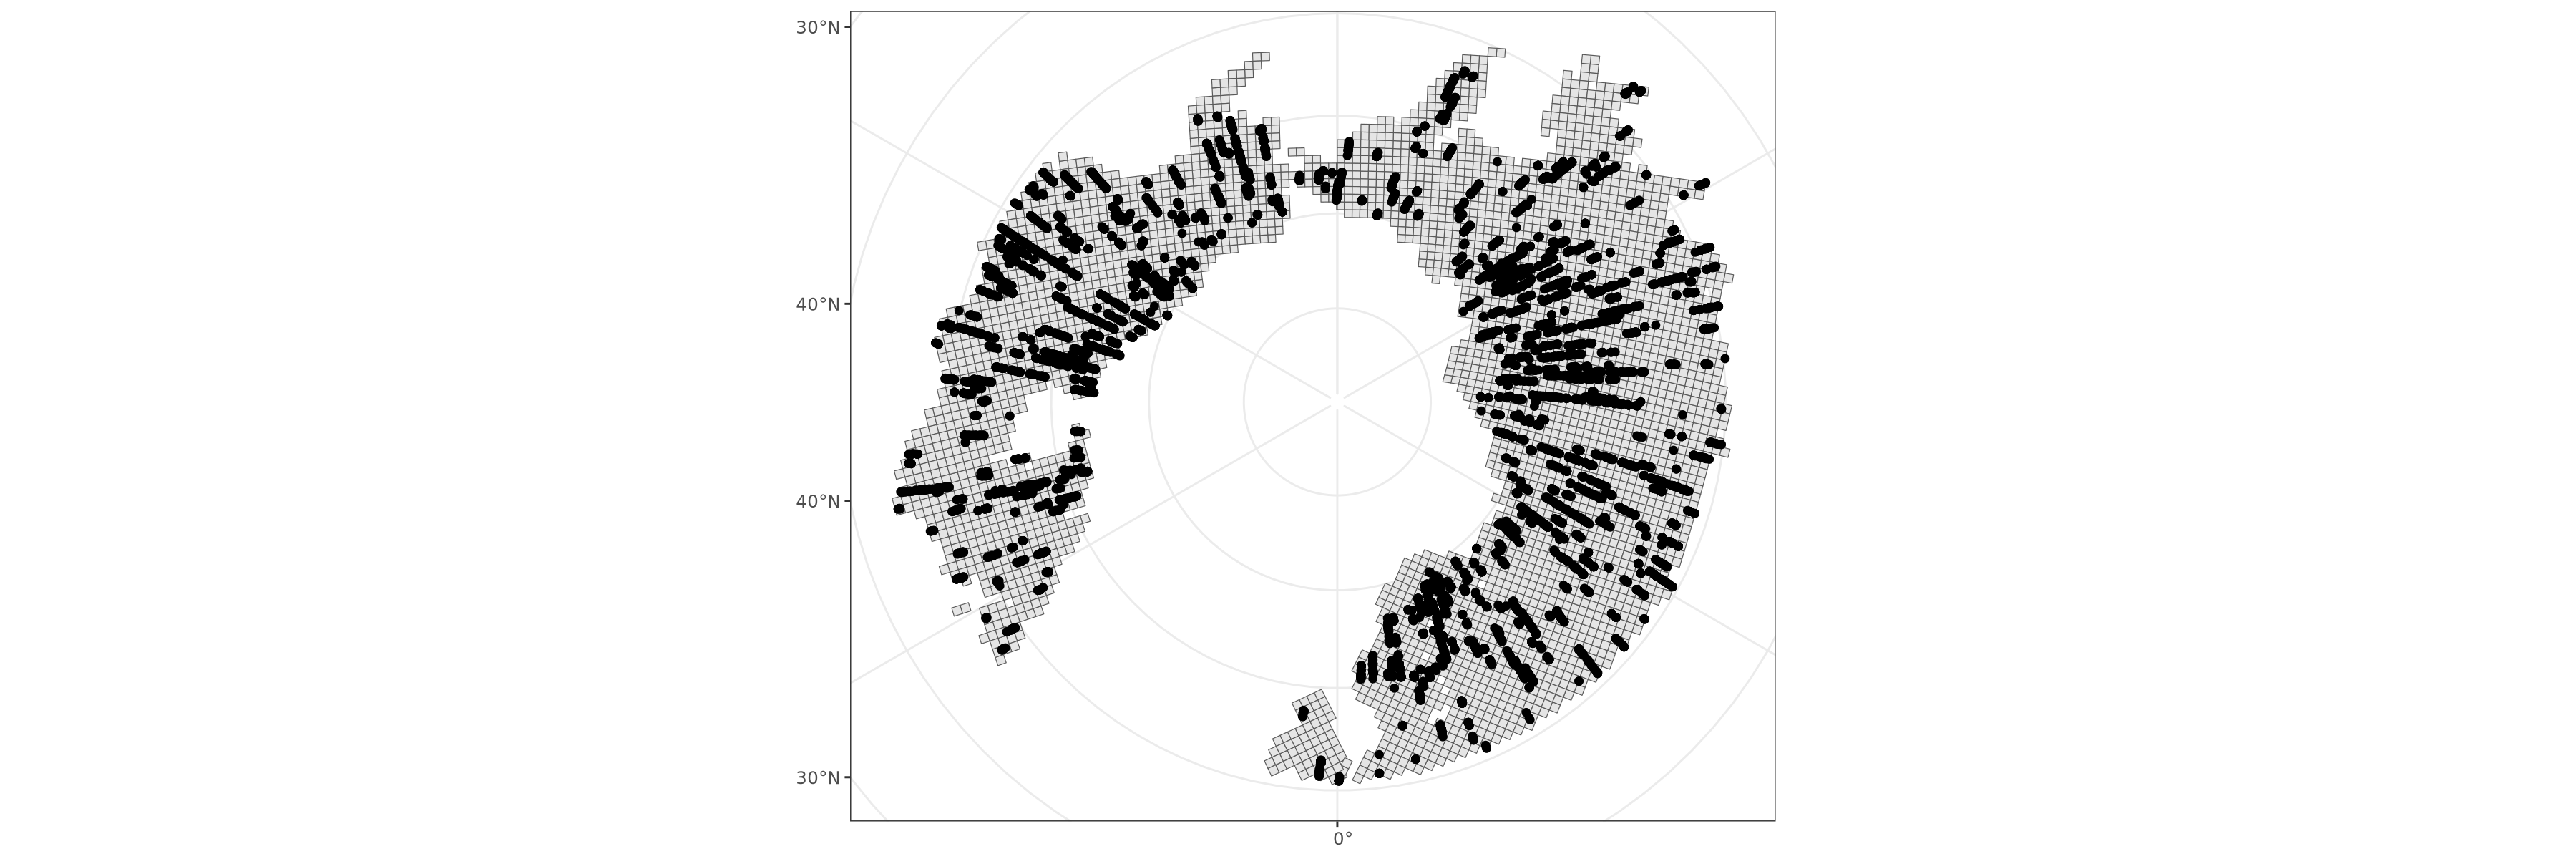

In [64]:
options(repr.plot.width = 18, repr.plot.height = 6, repr.plot.res = 200 , warn = -1 )

ggplot(boreal_tindex) + 
    geom_sf() +
    geom_sf(data=boreal_training_atl08_sub ) +
    coord_sf(crs = 3995) + 
    theme_bw()

In [5]:
map_extent_boreal = raster::extent(-180,180,42.5,90)

### Maps of ATL08 n_obs for 2020

In [6]:
map_theme = list(
    theme(legend.text=element_text(size=rel(0.35))),
    guides(fill=guide_colourbar(title="# of filtered ATL08 30m obs.", title.position = "top", label.position = "bottom"
                               # , keywidth = unit(4, "cm"), keyheight = unit(.25, "cm")
                               )
           ),
    scale_fill_viridis(option = 'turbo' 
                       , breaks=c(0,20000,40000)
                       , limits = c(0, 45000)
                       , labels=comma
                      #, trans='log'
                      )
    )

In [7]:
boreal_tiles_gcs_ATL08obs = st_read(paste0(DATA_DIR_ATL08_SMRY, '/boreal_tiles_v004_ATL08_filt_smry_nobs.gpkg')) %>% 
                                st_transform(4326) %>% 
                                dplyr::filter(tile_num %in% boreal_tindex$tile_num)

Reading layer `boreal_tiles_v004_ATL08_filt_smry_nobs' from data source 
  `/projects/my-public-bucket/boreal_HLS_ATL08_metadata/data/boreal_tiles_v004_ATL08_filt_smry_nobs.gpkg' 
  using driver `GPKG'
Simple feature collection with 4956 features and 8 fields
Geometry type: POLYGON
Dimension:     XY
Bounding box:  xmin: -6111478 ymin: 1233304 xmax: 6308522 ymax: 10323300
Projected CRS: unnamed


ERROR: [1m[33mError[39m in `stopifnot()`:[22m
[1m[22m[36mℹ[39m In argument: `tile_num %in% boreal_tindex$tile_num`.
[1mCaused by error:[22m
[33m![39m object 'boreal_tindex' not found


### Sum # of ATL08 30 m obs per `year` for a set of tiles

In [114]:
smry_year_ATL08_obs = boreal_tiles_gcs_ATL08obs %>% 
    as.data.frame() %>% drop_na() %>%
    summarize(
        'c2020' = sum(n_obs.atl08v005),
        '2019' = sum(n_obs.atl08v006_2019),
        '2020' = sum(n_obs.atl08v006_2020),
        '2021' = sum(n_obs.atl08v006_2021),
        '2022' = sum(n_obs.atl08v006_2022),
        '2023' = sum(n_obs.atl08v006_2023),
        '2024' = sum(n_obs.atl08v006_2024)
        )
smry_year_ATL08_obs.m = melt(smry_year_ATL08_obs)

No id variables; using all as measure variables



In [117]:
head(smry_year_ATL08_obs)

,c2020,2019,2020,2021,2022,2023,2024
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,22391668,27713038,46357213,26857160,44898587,26943493,30317733


In [115]:
smry_year_ATL08_obs.m['domain'] = 'DAAC'
smry_year_ATL08_obs.m['version'] = 'v6'
smry_year_ATL08_obs.m[smry_year_ATL08_obs.m$variable == 'c2020','version'] = 'v5'
smry_year_ATL08_obs.m['value_scaled'] = smry_year_ATL08_obs.m['value'] / 1e6
smry_year_ATL08_obs.m

variable,value,domain,version,value_scaled
<fct>,<dbl>,<chr>,<chr>,<dbl>
c2020,22391668,DAAC,v5,22.39167
2019,27713038,DAAC,v6,27.71304
2020,46357213,DAAC,v6,46.35721
2021,26857160,DAAC,v6,26.85716
2022,44898587,DAAC,v6,44.89859
2023,26943493,DAAC,v6,26.94349
2024,30317733,DAAC,v6,30.31773


In [103]:
boreal_tiles_gcs_ATL08obs_df = fortify_sf(boreal_tiles_gcs_ATL08obs)

Regions defined for each Polygons


In [104]:
# Melt for facet plotting
boreal_tiles_gcs_ATL08obs_df.m = melt(boreal_tiles_gcs_ATL08obs_df, 
                                      id.vars = c('long','lat','order','hole','piece','id','group','tile_num','n_obs.atl08v005'),
                                      meas.vars = c('n_obs.atl08v006_2019','n_obs.atl08v006_2020','n_obs.atl08v006_2021','n_obs.atl08v006_2022','n_obs.atl08v006_2023') )

In [105]:
levels(factor(boreal_tiles_gcs_ATL08obs_df.m$variable))

[1] "n_obs.atl08v006_2019" "n_obs.atl08v006_2020" "n_obs.atl08v006_2021"
[4] "n_obs.atl08v006_2022" "n_obs.atl08v006_2023" "n_obs.atl08v006_2024"

In [131]:
theme_plot_text = list(
            theme(
                legend.title=element_text(size=rel(1.2)), # 1.25
                legend.text=element_text(size=rel(1)), #0.75
                plot.caption = element_text(size = 7)
                )
            )

In [262]:
YEAR = '2020'
VAR = paste0('n_obs.atl08v006_',YEAR)

map_theme = list(
    theme(legend.text=element_text(size=rel(0.35))),
    guides(fill=guide_colourbar(title=paste0("Per-tile count of filtered ICESat-2 ATL08 30m obs.\n(n=", 
                                             scales::label_comma(accuracy = 1)(smry_year_ATL08_obs[,YEAR]),")"), title.position = "top", label.position = "bottom"
                               , keywidth = unit(8, "cm"), keyheight = unit(.5, "cm")
                               )
           ),
    scale_fill_viridis(option = 'turbo' 
                       , breaks=c(0,20000,40000)
                       , limits = c(0, 45000)
                       , labels=comma
                      #, trans='log'
                      )
    )

ATL08obs_LAYER_LIST = list(
                        geom_polygon(data = boreal_tiles_gcs_ATL08obs_df.m %>% 
                                     filter(variable == VAR) %>% 
                                     drop_na(), 
                                                aes(x = long, y = lat, group = group, fill=value), size=0.1)
                        #, labs(title=YEAR, subtitle = paste0('n = ', scales::label_comma(accuracy = 1)(smry_year_ATL08_obs[,YEAR])) )
                        )
m_count_tile_icesat2 = DO_MAP_BOREAL_SP(MAP_EXTENT = map_extent_boreal, BOREAL_SHP_FN = wwf_circ_dis_fn, LAYER_LIST = ATL08obs_LAYER_LIST) + map_theme + theme_plot_text

[1] "Using sf and coercing to Spatial object..."
Reading layer `wwf_circumboreal_Dissolve' from data source 
  `/projects/my-public-bucket/databank/arc/wwf_circumboreal_Dissolve.shp' 
  using driver `ESRI Shapefile'
Simple feature collection with 2 features and 4 fields
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: -5281040 ymin: -60527.9 xmax: 3959203 ymax: 8747447
Projected CRS: NAD83 / Alaska Albers


Regions defined for each Polygons
Regions defined for each Polygons
Regions defined for each Polygons


In [ ]:
m_count_tile_icesat2

# Map Boreal EXTENT, ATL08, and Biomass

#### Read boreal extent, read tiles, then clip tiles to boreal extent

In [9]:
wwf_circ_dis_fn

/projects/my-public-bucket/databank/arc/wwf_circumboreal_Dissolve.shp

In [12]:
boreal_shp_fn = '/projects/my-public-bucket/misc_files/Ecoregions2017_boreal_m.shp'
boreal_shp_fn = '/projects/shared-buckets/montesano/databank/arc/wwf_circumboreal_Dissolve.gpkg'
#boreal_shp_fn = '/projects/shared-buckets/montesano/databank/arc/boreal.shp'
#boreal_shp_fn = wwf_circ_dis_fn
boreal = st_read(boreal_shp_fn)
boreal_albers<-spTransform(sf:::as_Spatial(boreal),CRS(crs_albers))

Reading layer `wwf_circumboreal_Dissolve' from data source 
  `/projects/shared-buckets/montesano/databank/arc/wwf_circumboreal_Dissolve.gpkg' 
  using driver `GPKG'
Simple feature collection with 2 features and 4 fields
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: -5281040 ymin: -60527.9 xmax: 3959203 ymax: 8747447
Projected CRS: NAD83 / Alaska Albers


#### Get only the boreal tile nums that coincide with the boreal extent

In [12]:
# #head(boreal_tiles_clip%>% as.data.frame())
# boreal_tile_num_list = boreal_tiles_clip %>% as.data.frame() %>% dplyr::select(tile_num) %>% as.list()
# boreal_tile_num_list = unlist(boreal_tile_num_list[[1]])
# length(boreal_tile_num_list)

## Map showing boreal tile extent

In [92]:
boreal_tiles_gcs = shp_fort_join(boreal_tile_index_path, ext, REPROJECT=TRUE)

[1] "Using sf and coercing to Spatial object..."
Reading layer `boreal_tiles_v004_ORNLDAAC' from data source 
  `/projects/my-public-bucket/databank/daac/boreal_tiles_v004_ORNLDAAC.gpkg' 
  using driver `GPKG'
Simple feature collection with 3902 features and 1 field
Geometry type: POLYGON
Dimension:     XY
Bounding box:  xmin: -180 ymin: 43.75195 xmax: 180 ymax: 78.53133
Geodetic CRS:  WGS 84


Regions defined for each Polygons


In [160]:
dim(boreal_tindex)[1]

[1] 3902

In [197]:
library(ggtext)

In [253]:
options(repr.plot.width = 6, repr.plot.height = 6, repr.plot.res = 300)

# Calculate variables
tile_size <- 90
n_tiles <- dim(boreal_tindex)[1]

text_data <- data.frame(
  x = c(0),
  y = c(90),
  label = c(paste0("The boreal domain and\neach ", tile_size, " km x ", tile_size, " km tile\n(n=",n_tiles,")")
           )
    )

m_boreal_tiles = DO_MAP_BOREAL_SP(MAP_EXTENT=map_extent_boreal,  
                     BOREAL_SHP_FN = wwf_circ_dis_fn,
                     LAYER_LIST = list(geom_polygon(data = boreal_tiles_gcs, aes(x = long, y = lat, group = group), size=0.1, fill=NA, color='black'))
                    ) +
  geom_label(data = text_data,
           aes(x = x, y = y, label = label),
           hjust = 0.5, vjust = 0.5,
           size = 3, color = "black", fontface='italic',
           inherit.aes = FALSE)

[1] "Using sf and coercing to Spatial object..."
Reading layer `wwf_circumboreal_Dissolve' from data source 
  `/projects/my-public-bucket/databank/arc/wwf_circumboreal_Dissolve.shp' 
  using driver `ESRI Shapefile'
Simple feature collection with 2 features and 4 fields
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: -5281040 ymin: -60527.9 xmax: 3959203 ymax: 8747447
Projected CRS: NAD83 / Alaska Albers


Regions defined for each Polygons
Regions defined for each Polygons
Regions defined for each Polygons


### Read in boreal AGB training (field) plots

In [258]:
geom_borealwide = list(
        geom_polygon(data = boreal_tiles_gcs, 
                     aes(x = long, y = lat, group = group), size=0.1, fill=NA, color='black') ,
        geom_point(data = boreal_training_atl08_sub %>% st_filter(boreal_tindex), aes(x = lon, y = lat, color=factor(month)), size=1),
        labs(color='Month of ICESat-2 obs.'),
        guides(color=guide_legend(title=paste0("Candidate training ICESat-2\nfrom boreal-wide sample (n=",dim(boreal_training_atl08_sub)[1],")"), override.aes = list(size = 10)
                                 , title.position = "top", label.position = "bottom", keywidth = unit(.5, "cm"), keyheight = unit(.25, "cm"), ncol=4
                  )
              )
)

although coordinates are longitude/latitude, st_intersects assumes that they
are planar

although coordinates are longitude/latitude, st_intersects assumes that they
are planar



In [259]:
options(repr.plot.width = 6, repr.plot.height = 6, repr.plot.res = 200)

m_tiles_borealwidetraining = DO_MAP_BOREAL_SP(MAP_EXTENT = map_extent_boreal,  
                         BOREAL_SHP_FN = wwf_circ_dis_fn,
                         LAYER_LIST = geom_borealwide
                        ) + 
        theme_plot_text

[1] "Using sf and coercing to Spatial object..."
Reading layer `wwf_circumboreal_Dissolve' from data source 
  `/projects/my-public-bucket/databank/arc/wwf_circumboreal_Dissolve.shp' 
  using driver `ESRI Shapefile'
Simple feature collection with 2 features and 4 fields
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: -5281040 ymin: -60527.9 xmax: 3959203 ymax: 8747447
Projected CRS: NAD83 / Alaska Albers


Regions defined for each Polygons
Regions defined for each Polygons
Regions defined for each Polygons


In [260]:
library(patchwork)

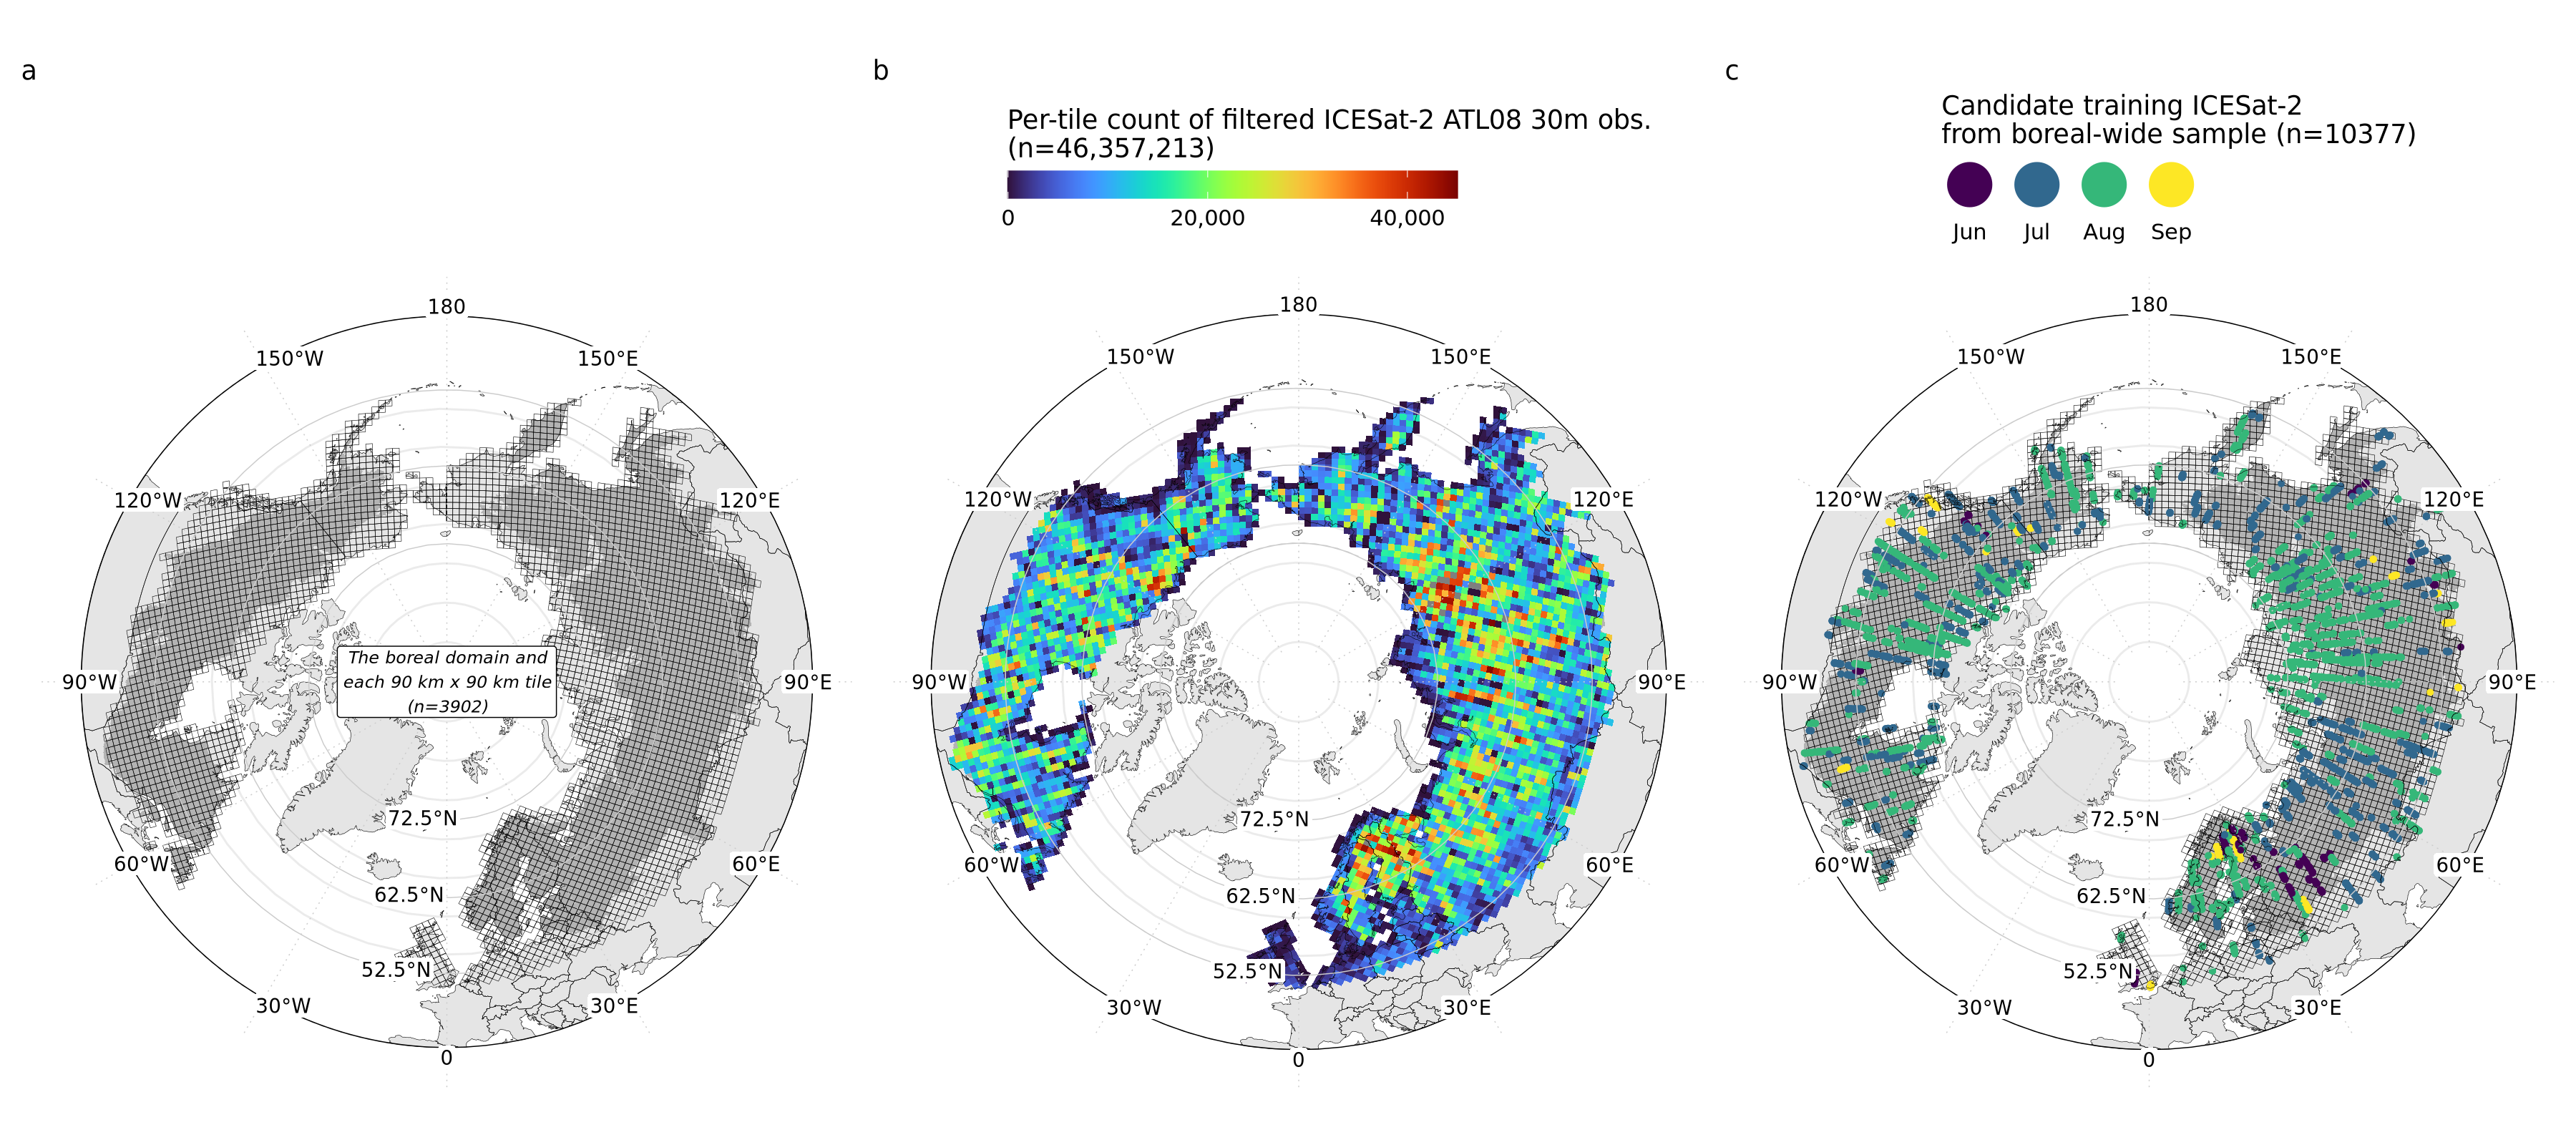

In [270]:
options(repr.plot.width = 18, repr.plot.height = 8, repr.plot.res = 200)

m_tiles_samples_combined = (m_boreal_tiles | m_count_tile_icesat2 | m_tiles_borealwidetraining) + plot_annotation(tag_levels = 'a')
m_tiles_samples_combined

## Export figure:

In [271]:
EXPORT_PNG_PDF <- function(m_plot_figure, OUT_FIGURE_DIR, DATA_NAME_STEM, VAR, EXPORT_TIME_STR=format(Sys.time(), "_%Y%m%d"), FIG_DIMS=c(8,16), TYPE='map'){
    
    for(OUT_TYPE in c('png', 'pdf')){
        
        map_fn = path(OUT_FIGURE_DIR, paste0(TYPE,"_",DATA_NAME_STEM,"_", VAR, EXPORT_TIME_STR,".", OUT_TYPE))
        print(map_fn)
        
        ggsave(plot = m_plot_figure,
               file = map_fn,
               device = OUT_TYPE, dpi = 300, width=FIG_DIMS[1], height=FIG_DIMS[2])
    }
}

In [272]:
EXPORT_MAPS_PNG_PDF(m_tiles_samples_combined, OUT_FIGURE_DIR, 'BOREAL_TILES', '_ICESat2nobs_tiles_borealwide', EXPORT_TIME_STR=format(Sys.time(), "_%Y%m%d"), FIG_DIMS=c(18,8))

/projects/my-public-bucket/boreal_AGB/paper_figs/map_BOREAL_TILES__ICESat2nobs_tiles_borealwide_20251030.png
/projects/my-public-bucket/boreal_AGB/paper_figs/map_BOREAL_TILES__ICESat2nobs_tiles_borealwide_20251030.pdf


In [269]:
OUT_FIGURE_DIR

[1] "/projects/my-public-bucket/boreal_AGB/paper_figs"